<a href="https://colab.research.google.com/github/wujh03/MSSP6070/blob/main/Assignments/10.28case_study_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import pandas as pd
import matplotlib.pyplot as plt


# Clone the repository
!git clone https://github.com/wujh03/MSSP6070.git

# Read the dataset
df = pd.read_csv(
    "/content/MSSP6070/data/InternetSales.csv",
    encoding="latin1",
    low_memory=False
)

print(df.shape)
df.head()


fatal: destination path 'MSSP6070' already exists and is not an empty directory.
(60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [19]:
print(df.columns.tolist())

['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'CustomerPONumber', 'OrderDate', 'DueDate', 'ShipDat

In [9]:
# Q1: Internet sales by year and country

# Convert OrderDate to datetime
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

# Extract year
df["Year"] = df["OrderDate"].dt.year

# Group sales by year and country
sales_table = df.groupby(
    ["Year", "EnglishCountryRegionName"]
)["SalesAmount"].sum().unstack()

display((sales_table / 1000000).round(3))

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,0.021,0.004,0.003,NaN,0.001,0.015
2011,2.564,0.572,0.411,0.521,0.551,2.458
2012,2.128,0.308,0.648,0.609,0.713,1.437
2013,4.339,1.086,1.579,1.762,2.124,5.462
2014,0.009,0.009,0.003,0.003,0.004,0.018


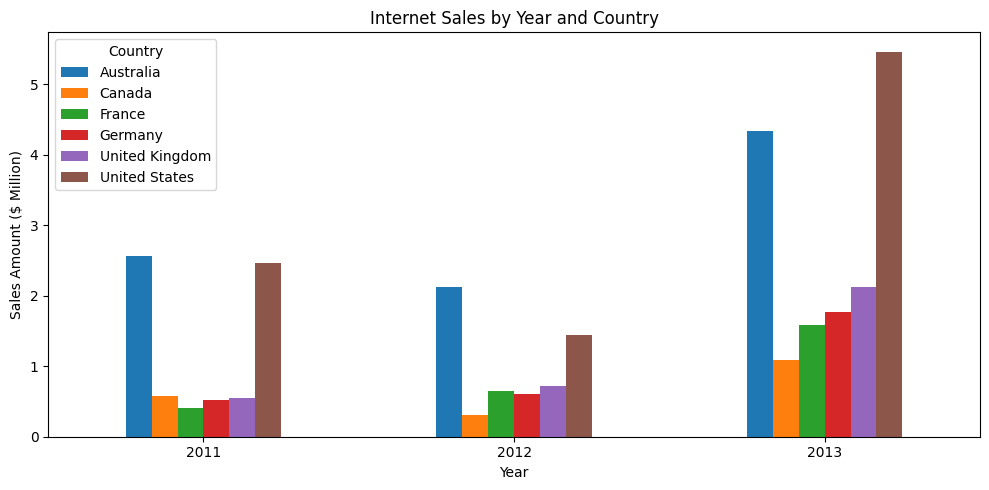

In [10]:
# Plot sales by year and country

# Select complete years and convert dollars to millions
sales_plot = sales_table.loc[2011:2013] / 1000000

# Create bar chart
sales_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Internet Sales by Year and Country")
plt.xlabel("Year")
plt.ylabel("Sales Amount ($ Million)")
plt.xticks(rotation=0)
plt.legend(title="Country")
plt.tight_layout()
plt.show()

In [11]:
# Q2: Yearly Income and Gender by Country

# Keep one record for each customer
customers = df.drop_duplicates(subset="CustomerKey")

print("Number of customers:", len(customers))

Number of customers: 18484


In [12]:
# Calculate income statistics for each country
income_stats = customers.groupby(
    "EnglishCountryRegionName"
)["YearlyIncome"].agg(["min", "max", "mean", "std"])

display(income_stats.round(2))

,min,max,mean,std
EnglishCountryRegionName,,,,
Australia,10000,170000,64338.62,31830.00
Canada,10000,170000,57167.41,20251.52
France,10000,110000,35762.43,27277.40
Germany,10000,130000,42943.82,35493.58
United Kingdom,10000,170000,52169.37,48431.99
United States,10000,170000,63616.83,25706.48


In [13]:
# Count customers by country and gender
gender_table = customers.groupby(
    ["EnglishCountryRegionName", "Gender"]
).size().unstack(fill_value=0)

display(gender_table)

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


In [14]:
# Calculate gender percentages by country
gender_percent = gender_table.div(
    gender_table.sum(axis=1), axis=0
) * 100

display(gender_percent.round(2))

Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


In [21]:
# Q3: Product Category and Average Price

# Create a function to classify products
def get_category(name):
    if name.startswith(("Mountain-", "Road-", "Touring-")):
        return "Bikes"

    elif any(word in name for word in
             ["Jersey", "Shorts", "Gloves", "Socks", "Vest", "Cap"]):
        return "Clothing"

    else:
        return "Accessories"

# Apply the function to each product
df["Category"] = df["EnglishProductName"].apply(get_category)

# Check the result
display(df[["EnglishProductName", "Category"]].head(10))

,EnglishProductName,Category
0,"Mountain-100 Silver, 38",Bikes
1,"Mountain-200 Silver, 38",Bikes
2,Fender Set - Mountain,Accessories
3,"Touring-1000 Blue, 46",Bikes
4,Touring Tire,Accessories
5,Touring Tire Tube,Accessories
6,"Sport-100 Helmet, Red",Accessories
7,"Short-Sleeve Classic Jersey, S",Clothing
8,"Mountain-200 Silver, 38",Bikes
9,Fender Set - Mountain,Accessories


In [22]:
# Calculate total sales for each category
category_sales = df.groupby("Category")["SalesAmount"].sum()

# Sort from highest to lowest
category_sales = category_sales.sort_values(ascending=False)

display(category_sales.round(2))

,SalesAmount
Category,
Bikes,28318144.65
Accessories,700759.96
Clothing,339772.61


In [23]:
# Find the category with the highest sales
top_category = category_sales.idxmax()

# Select products in that category
top_products = df[df["Category"] == top_category]

# Calculate average unit price
average_price = top_products["UnitPrice"].mean()

print("Top Category:", top_category)
print("Average Unit Price: $", round(average_price, 2))

Top Category: Bikes
Average Unit Price: $ 1862.42


In [24]:
# Calculate total units sold by category
category_units = df.groupby("Category")["OrderQuantity"].sum()

display(category_units)

,OrderQuantity
Category,
Accessories,36092
Bikes,15205
Clothing,9101


In [25]:
# Calculate revenue share by category
category_share = category_sales / category_sales.sum() * 100

display(category_share.round(2))

,SalesAmount
Category,
Bikes,96.46
Accessories,2.39
Clothing,1.16


In [26]:
# Calculate average unit price by category
average_price = df.groupby("Category")["UnitPrice"].mean()

display(average_price.round(2))

,UnitPrice
Category,
Accessories,19.42
Bikes,1862.42
Clothing,37.33


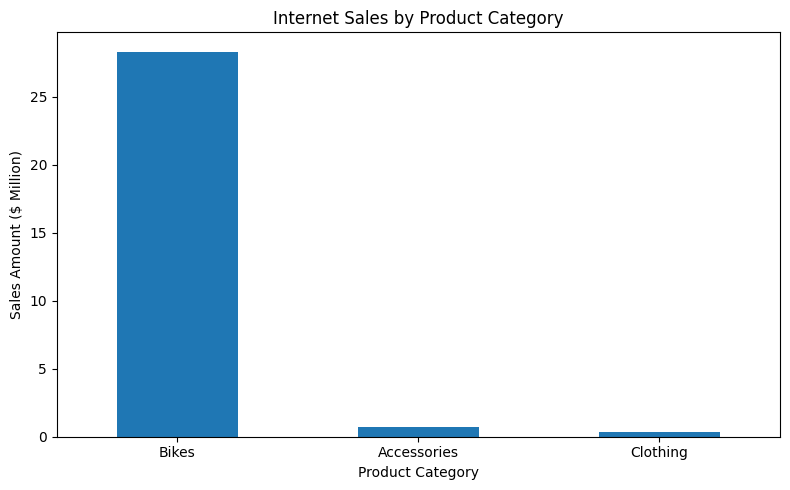

In [27]:
# Q3: Plot sales by product category

import matplotlib.pyplot as plt

# Convert sales to millions
category_plot = category_sales / 1000000

# Create bar chart
category_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales Amount ($ Million)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# Q4: Homeownership and Sales

# Calculate total spending for each customer
customer_sales = df.groupby(
    ["CustomerKey", "HouseOwnerFlag"]
)["SalesAmount"].sum().reset_index()

display(customer_sales.head())

,CustomerKey,HouseOwnerFlag,SalesAmount
0,11000,1,8248.99
1,11001,0,6383.88
2,11002,1,8114.04
3,11003,0,8139.29
4,11004,1,8196.01


In [29]:
# Compare spending by homeownership
housing_stats = customer_sales.groupby(
    "HouseOwnerFlag"
)["SalesAmount"].agg(["count", "sum", "mean", "median"])

display(housing_stats.round(2))

,count,sum,mean,median
HouseOwnerFlag,,,,
0,5982,8973327.42,1500.05,209.96
1,12502,20385349.80,1630.57,342.00


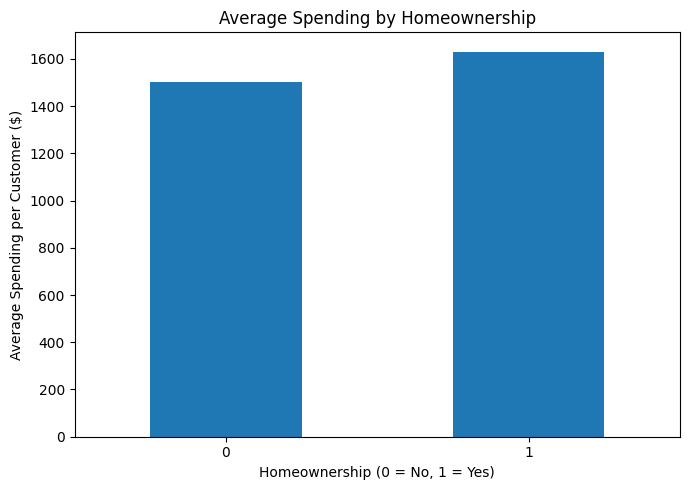

In [30]:
# Q4: Plot average spending by homeownership

# Select mean spending for each group
housing_plot = housing_stats["mean"]

# Create bar chart
housing_plot.plot(kind="bar", figsize=(7, 5))

plt.title("Average Spending by Homeownership")
plt.xlabel("Homeownership (0 = No, 1 = Yes)")
plt.ylabel("Average Spending per Customer ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [31]:
# Calculate percentage difference in average spending
homeowner_mean = housing_stats.loc[1, "mean"]
non_homeowner_mean = housing_stats.loc[0, "mean"]

difference = (homeowner_mean - non_homeowner_mean) / non_homeowner_mean * 100

print("Percentage Difference:", round(difference, 2), "%")

Percentage Difference: 8.7 %
